<a href="https://colab.research.google.com/github/NITTALOKESH/MLA0204-FUNDAMENTALS-OF-MEACHINE-LEARNINGS--NITTA-LOKESH/blob/main/Experiment%205%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset loaded successfully
Total samples: 150
Number of features: 4
Flower classes: ['setosa' 'versicolor' 'virginica']

ANN training completed successfully

Accuracy: 96.67 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



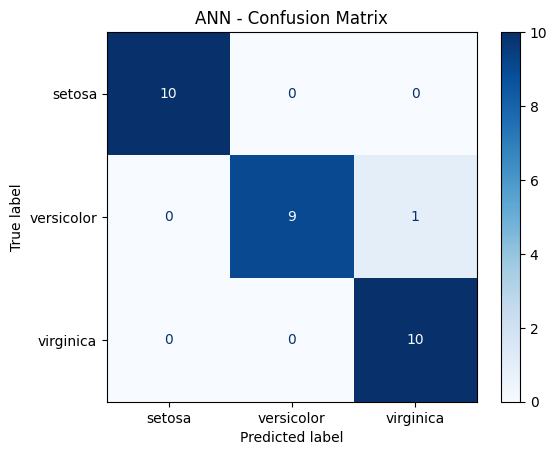

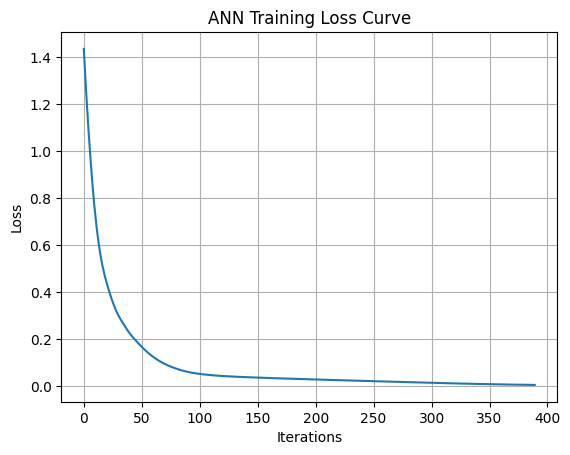


New Flower Measurements: [[5.1 3.5 1.4 0.2]]
Predicted Flower Species: setosa


In [1]:

# Experiment 4: Artificial Neural Network using Backpropagation

# Step 1: Import libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Step 2: Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

print("Dataset loaded successfully")
print("Total samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Flower classes:", iris.target_names)

# Step 3: Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 4: Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 5: Create the Artificial Neural Network
ann = MLPClassifier(
    hidden_layer_sizes=(10, 8),
    activation="relu",
    solver="adam",
    learning_rate_init=0.01,
    max_iter=2000,
    random_state=42
)

# Step 6: Train the network using backpropagation
ann.fit(X_train, y_train)

print("\nANN training completed successfully")

# Step 7: Predict the test data
y_pred = ann.predict(X_test)

# Step 8: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", round(accuracy * 100, 2), "%")

# Step 9: Display confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Step 10: Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=iris.target_names,
    zero_division=0
))

# Step 11: Plot the confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
).plot(cmap="Blues")

plt.title("ANN - Confusion Matrix")
plt.show()

# Step 12: Plot training loss
plt.plot(ann.loss_curve_)
plt.title("ANN Training Loss Curve")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# Step 13: Predict a new flower
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])
new_flower_scaled = scaler.transform(new_flower)
prediction = ann.predict(new_flower_scaled)

print("\nNew Flower Measurements:", new_flower)
print("Predicted Flower Species:", iris.target_names[prediction[0]])
